# Phase 1 — Real dataset audit

Use the same Kaggle session as the previous notebook. This notebook includes its
own audit code and reads the downloaded repositories without modifying them.
It produces a review bundle and candidate splits. It never silently converts
unknown label values, invents capture metadata, starts training, or freezes splits.


In [9]:
import base64, hashlib, io, os, sys, zipfile
from pathlib import Path
payload=base64.b64decode('UEsDBBQAAAAIAK+QWV2lp73/MQAAADAAAAAPAAAAc3JjL19faW5pdF9fLnB5U1JSCspPTFFILkpMzlYoTk3PTc0rSSzJzM9TKEotTk0sSs5QKABKJaan6ikpKXEBAFBLAwQUAAAACACwkFldnzSAJHoBAAD9AgAADQAAAHNyYy9hdG9taWMucHltUrluBCEM7ecrLCpQJhSpopWmywekSBlpxSwmIcslYPb4+3Ds7BGFCuzn92w/CCFvSxSzQYgYjNihRZc3oIQ2KOEYdcYEDg8YVwAIB3jSKWv3VWJpMZkTQgZtg48ZfpJ3692nQUVvIYj8bfQMl/B7ea6QjDaoojUMg0QFInurd9umS2vZ2HuIbDNAOTUEU2NoaXaN8iBiaZ3bvdSR9keaPuKCY2936/ft2UuUHJu2jyKeC+PaR6lP9U4Ly3THO0KIqPSpx5ywCE9AOBkhLarGCc82kE6e47m3W89Rl5Z94kr6gI5WYXKcCQORIOWIwt6wDd/mpT3FHlI9xpVZ0jd9TFWBdHY7umLKLM5TdkMVxMVBeh18hNsSlXbCmLvGtao1bd62wHSrY5u/4osz2u3vEBdD2zTb+ikudh6EKR70+n/cNsLOUqyLWSfuiKsmrXxcLjYk2vhG0E4Wl6aX4kf5Vts9nrv5rNr06Qjj6HZeIiVLVs+vhJXN/AJQSwMEFAAAAAgAsJhZXf+alAGBEQAAszIAABwAAABzY3JpcHRzL2F1ZGl0X2thZ2dsZV9kYXRhLnB5pTprk9Q4kt/7V2iZiJMNbndXM7BsgWeDHXrmiJtpCGBuL6amzuEuq6oEfo1k94Pe+u+bmZLlR7kauKuAtiVLqVS+M6UHDx68Lq5EUZfqlimRZOy/ks0mEyxN6oQlRcoqVabNSsDHKymuk0v4toJ+CQME01Umax0eHV2IK6GYJFBMiz8bUcCcXNQJApozLXOZJUrWt2yVNboWSrNECVYW2S0ucXPLNqpsKoB1UbI8KeRa6JpJzdaq/CwK1hS1zAChoqyTWpYFq0oLD5GURSoqAX9wVYRrsBVpePTgwYMjmVelquHDpkqUFm17pa/a122it5m8bJsfdVkcwco5q5IaPzD74S0020EKVi5z13Jg9a1uXz/Lai0zcXQEfSGCCmWhhaq904DpWnkIzotjHBPHfqiELrMr4fkwVgEl9WK29H2DiFarMKnLXK5aXK5h+yImVI/O/+fD+cX7128u3rOI3fHwY7XhAcOnMC9VYZ6XeUXPWq7b55rvjo6OUrFmiEeR5CImXnjIOi3qgH0St/78iMHvO/YzfmJFk18KJVKkz2orNNNb4EaxYQn7+c3bd0wCKwC0BKFYlbjlK+DalchuQwIj18wCZ1HE+I8qWX36Nam4WQR/OcKFvSgRrpsso6anuIfQ/0gf+d7f5+wPD97+8P2/c4OimwzgaUIHDn9K1I0qGHe7XCUV9IiYs0dmfGj2PTOQ7PiLshCWPrps1ErEWXJbNjWRJ1ZlWVvapFKJFSlSRHLSG3DCXwlR0TZP7MY5zUnUagt0gRludm9sCPJjxuHqWbkCnfP8blcWw0XF1qViFahBByZUm6y89HitElnEMt9wH+lShVLHMMjzB7QhXECRkizzvMqK3wlSyXcTaBHswnVawFlyyQNeg7LSGvYVe31/SUs4a6Fhl+0eSAIcquJG6lpDr8i0YItlKyOg7P3phKAhmJvSESOFhWVhjMOAnOIGUF3VIo2vZnxqeJh/wg0SyLj8FH1QjejIcy3rbavI4e+y+gmenkXDZ4lmn4dihlQC4oEYAJk+g8KvywwA91FtfzVYJFQB5vWwOaHJYSulPauwN9+SyIBBPimRkZ7FddkH2YGYQIIEKZFA+P9OskacK1Uqj/9W6GQtmBNF9vvrt2QM+SQanmewBloLVSRZnNS1Yj/8wGZPffYf7LSc/fUUfj6qOzTOsPG1qLy/zTNZfEJyDtCZxgQJYnBxcotyY2nkJK3XB24vjS9vQcI8/y/RZ2qb7Xw1tc4RLJo/J2vOvqVgYMHbPQcvJ9AOCuuwdAXyOdrC59DORzXs8a8bNalMrbqAwHjdANjLrGcqxjivAWlEAVAFAwdWOq8yUfc5bsxcAALdAMZ3I+g7PrCS3ZfF6dLaj55XifME/Emrk5aulludHWg5di/av0qtkdQdge30Obtz7x12uslQw+521CY7CVKMwqTBiYrU27OYD3lfTdBmkuPW5Kat6FCXbtZreRNm5bVAMQOQnRseSs537A0GOkrkJQhAWq6aHOgDpO8FNAaaAElRwoQrGQQ8+aXcNBDmhAN44O1gTwaJWuR79sfAMnYaSK8/oa9Hqyyy9o1PCDfsFSCHEEhptHqeAXNACwwO8HcxP0bZsIOXk4MvQak+Db6YtRBFw6P9RSZ4/5LIUTYa9i4VAbiDPztgvYGygNZyx07YHRJnN9Kv3hhLvr4Im69WaBE+eAxkufZknmyEDhhSUltyZGINuqHkZovi5WTcDPWDrsdM6gs8TmXIJVF7+O6zv0TUIGj3S/9vhcHsROQVBL/gW1KwLrB/s/DuOeOTDDCiwc2oGLkLuk2ioaM7qwkOn+MOGX8xPztd7oL7wRIcB9UsMgBrgB27FSzYoQ1ZeMCZgMhDPLLkpXcTfViJsYAJ0tIyLGlS2YvJAgaYVGi+tBBp9P1ZwOotcHgLBIswpGttkImlIZ6tbtGZF5WxExhyv339S/v9NW4pMI9XKrmmQWaFNtozrbG7BpabDxMRy74feSfWDRm3umRgKRSF+GZrDDIaym+es9W2LGFiwgpx3SLhrJglqV3URDY2m+gFNsa2oxNZOHS8LvBEI2GDXQrzsL0XwZ50oeU9n8nUBF9aBHzdASAusjz4dW8Fl07AHOPj8a3tPTHiOegi+W2BLK1MrkqVgtILZA08IY8Bjmgw1UQ2kE7zn0ZDsNDx1WwKBh3KF9xIywZQhuWAFXuUGnHDtE56wf2oa0STw/CI8G6uI/agh4CZfYqblahqdk4P9FqgMkSgbveGXmFSYULuYZZLPb5vExkF8WkKu7WCe8K47TPWiDs/7dJPEN9a4moBI95hkGCMMb6hQbB07JAY8AN/aDU1Gf2eXR9naT3o40/tah3vvoIUXyZH+wPhgmCvEa7TWrt2x+ir7Jbb8IV2NFxrb9f4o/yFDFdYAg5eB5CyF8PpaRdPQ50ch0YDajBTP/9jIvh2MyAiggh6f8AYE7edLyICFhfQKKow0YlSya1nBk8mADA2hFg0x1Tj8YF9mVF6m1RiAaqHThljpccB+95Hz4wduBqE4TBwEYZhwE6XCNE1Z8uvHXm2PBBBmZ2NfcCPZVaqQWgIXklQB8hclckVOAMK5UAeqgq8xSFejHYJOH1PwesUzo/p+9mTJ9+E6weVQCJD3uX/j69hco+K93IXQqYzZICROC0/C+zyuh3PMH5wrdNDTNjf1K8gluBPIUI3xj4tiWKmIkXLTWzgCgFoI6RNIf9sBKIyKaAYBJnhYW1LAz57ASnKKUhVgDzYTaN6CekgVZcQNPuBnfqgD/VtJTxcVBb1M/8hzJ7eZpOhJvOq1BIrBJYjFu1LcHa5wKWfs89ClbZDs9P9sE9ksAcXS2GJFqmDIdVXYR11c78d/TV3EoXGo4cGwL1zrd0U1vqgbdkLsmEzFmtaxaPc15DK31ma+c9tkRloBcZadLLu0JgW9VGdyvg+F9E4X3ey5pTaUOX2PiA22Z4I9SB2mS5ptT9jizHWNVbVbNoPdQLx62T9of3pHLPTgUk2iuh8xC+cQmHQS8/7W/DMt8Fz+E7oJAdKFZvwl5cXP/7+5r0/QSOsxwN4EAqP8/BjKQuPzzhqz6UpEvJTTj7ykgw3obOYB7P5EvSibc2PwUiH6yyp/eBsfxEb4bWu+c4kR7FM+byNPR7xOX9Ebpi3Zdu5C0u44xWfdyHKpIwZ0HyO7r/zv72yHECjNJ1G9Cl/AB6oUtxNcI50H2JspJXPRxbnPjxjMJlnT57yuT0VCU17iHlXM/PDrbhJJcTUh+G2+B4C3d/Bt0G+D+qwBPptcCt5I7JDgB0fyfH4IeRlZQpUf2Q66/IbFiJZ53NQd3qbn86e3uwwO7mWaQ0fDEhqQOdWYErc9prWAcBolfBAo4BwF4uKJKhriM1qz2r6D+BBcpEUgOhuXz96Cc+UjoxVhKON5nP8OwL2lZEyDR1Ey0gTs8ru5M6pGLzbmg+NxiKCPZt63ztlLCFxL9AUQhgtKjCYtSl2UokcniYLhEQb0sOtUCH7sBW31tdbcMC15BLUZcsUBLQn7lhzeNpYIMw/G0gr2LbJk8K6BVOws7FRxEjrIFraCA+dibU9vsuKsEwKO5a9KOV6C0mKhbCQSwxv5Dipab9F7bvrGkZPshshuy+27iKpI7cneVGb034qyuvCHAXqYQVVQmRVXqPlFUWTC4VV6HZHHYY009bGeqeKMHPhrOmSIC06sVqGdKbsgVQFMx/PP/uVWIIwpEHbi9j0Md6XLbt/S+clYQav/UkLeiyH4jsxAF1TR0XcwHCTHEfQ2zfSDEd+pKIoiYocBa0liiqditLExcflSNFAzfEzYjQwYBTd0+zxhwGAFKQ0Kah24aHvNbwiA7UMZk/9/8VOC6bX7YeXso5XYGrqUdoH3DFIYT7fAn8xmZgdYM/HfcNkJbUzSgmYnaEUBfySzy2ivd7DNUz744Qtn9MjMHuMW8TB5tm3CWuJuQmR3QUFpLEtzbve6Sh0ZPge9E2ZKrUGxSzoaK+rhmDVd7RtqnzvbXv3wO+J4VdIIUEl8aX5mDd0Fzhiuq5Bh+boBi2//KnJMPIKtAJJR0DoakCrKcwevwOcVKD7TOkWBjb/E54vosfPGeQq4oDdvXjzgYF7wjsGqYmPVbGh/BFvZYTv6OFh8degBiEhHpfZ8t3gOMhVl7TIyEkEeFKTyAKC1IC1vhOJ1i+WDitybRPCLDwGQ06Pi3bh2aBK2VYm7UucrMCJaGmn2k7YubrFqU/85ciyairMUCH8Tg3YhbtS5mSFOEuyOZDBKOq86cDAom8y0P0XZ/cVsjBJwoPWstlse4zpnde3WCI2PefNv1D4Ai5ClNWs15loMXHfMGHKkxtvFuSQEPRwPZ4FFOj0+x62jPN7wtmTgrCpEE3vzuskYOPPWxlAasgXhck2nDhYHdoMNciuuOvUzCqZZcBIs8jDkUY4KcJ0sWxqPmVGomhQrSWMDhqy/gZBgDxvDC0YKbcf8KZItJabAhTJkopMOemJnusm95RDOor0nnyZsxndO5m56ybsjd75Oxtv2EteeGFJg0HPk9jGm3w+A+Wpk7qBxIX/+PLi1etXLz+cx6Dz8U/v3vx+foHKBaoN6Q/83Tfr3GyAz80TYlOzNvgJW9bnRpzB0pvy/j6IDCyerWfx+YL/cwu2KFrRyXh39+w6kUAnFGKQtWO9FaJu4z/+RW8zbQ81mNXk1gWmz63T792gs4qF99zQFks8msQaTGsO26gTFCAHN/kViFyIRB2nDRYwUHNNsEw2T7OtaBTeblhRqJsDarnU2sXRLdYh+Blap7uWZo/ETrizCXHL9BC/86Bt+odm9txO6/XbmdQ6OJHSwn4GY6b1etz53J6SUp16Ank0czfhSl9x3xSw+TUPCnGdyUJEnJsqdg2JZj60nISeimBi+Equ6n9S0zMjA2BYliL/ddTz2YGtGASmLBC4gDnoVDfoq7U/sWJIjy0kvmJ836s/AAyC9jClmitzNN47abXjOiR3+9rvAH/Hfqvw5JKSUoz78EqJZpVQe7EL+Fr6mpKsKTDnJGJgvXo3HVbbUosiWnQx6sBfm+sN027YnGu1PnYURVdlmUUL9W1+chgoG9TouhN4nYmYIzT783At8lbPAvRN2PT7DolMRmRKYyBK5mwl8P769Flg7vPQQv7D2ZMnYKmv0Qj1PGiqkuvIHUqH+McjiP6AZBNBn4U7yqUQUtQ7oenCS5Cw0fmPq+5BGhHMzp6Nyngot3ugSJj7kH6ZgBPsFQovzl++O3//YbgAno9nya1d4zJDRhCqwZiaXaUGHQE4uSAEat4DjIoHGHt6tt+ACBD94Tyk7k1AZeABeb1uwohsgQU5dRWPWBdWiQYICDPwbh4iVSSy/9HZ2YjEyP2wBhkE2tkxj/1glBI84uxfkH3JjSySDNIDqmiftBvmYH+yLOKXGR4Lj8TS1IGdHTROLjaf6ILxnw1Eu/Vt9LdT35ZMPmylttfA8SJse9NJM/Bh5n65vbHCBIwxl6skXRxeJ+AH0/CQPXcwrSHvInFMQqpwcPPRHdv63cVYG5mMznX7d776cXA1uu/Fww0EM+1BIV2QrfWyvb2CV0Siuy5iMRFAbMtCaKkpLYjpyJbP+wWgYByqDDhsohSTWZt5Jlzx9+KXCU9pJrSOcgTYXKvn858SiCYDc2sA2BDDHpBO9sNBj05XUmKzc8sR0zAkqRQWCrA/TJu80p75GEjKEaJWkN3FK/x4dHQEhI9jqqLEEPTGMQbdcWxvhdPVfRW1l/jDl2pDsvWW+rHWu1KS6otRHIPgxbHfmxcmaRondorHj49RBo5RBniAZ1ARCkbQcqx3XnJguiHE/20uRa5mJpApSMU6abI6+v7s3lmouMfubKmbb9NbtdGRnUkPnKu7S0jYCikomjy6c+fCsxfRxNAX0dmTJ529susIc146OonLG4jpLwX8q68F6PiMYMN8a17MRS1apLutRU17Y4veKa6fwMQ/+jdQSwECFAAUAAAACACvkFldpae9/zEAAAAwAAAADwAAAAAAAAAAAAAAtoEAAAAAc3JjL19faW5pdF9fLnB5UEsBAhQAFAAAAAgAsJBZXZ80gCR6AQAA/QIAAA0AAAAAAAAAAAAAALaBXgAAAHNyYy9hdG9taWMucHlQSwECFAAUAAAACACwmFld/5qUAYERAACzMgAAHAAAAAAAAAAAAAAAtoEDAgAAc2NyaXB0cy9hdWRpdF9rYWdnbGVfZGF0YS5weVBLBQYAAAAAAwADAMIAAAC+EwAAAAA=')
assert hashlib.sha256(payload).hexdigest()=='8910a8953638e18c37d7cce637d35fa53a69b58326498ce15309cb87550a1d00'
project=Path('/kaggle/working/road_crack_data_audit_v2')
project.mkdir(exist_ok=True)
with zipfile.ZipFile(io.BytesIO(payload)) as archive:
    for name in archive.namelist():
        path=(project/name).resolve()
        assert path.is_relative_to(project.resolve())
        if path.exists(): assert path.read_bytes()==archive.read(name), 'Existing code differs; choose a new project directory'
    archive.extractall(project)
os.chdir(project)
data_root=Path('/kaggle/working/road_crack_phase1/data/raw')
if not data_root.exists():
    raise RuntimeError('Previous data directory missing: restore/clone the datasets first, or update data_root')
print('Using data:',data_root)


Using data: /kaggle/working/road_crack_phase1/data/raw


In [10]:
import subprocess
from datetime import datetime, timezone
# New output directory on every run preserves earlier audit evidence.
run=project/'artifacts'/('audit_'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ'))
result=subprocess.run([sys.executable,'scripts/audit_kaggle_data.py',
    '--data-root',str(data_root),'--output',str(run)],text=True,capture_output=True)
print(result.stdout)
print(result.stderr)
run.mkdir(parents=True,exist_ok=True)
(run/'execution.txt').write_text(result.stdout+result.stderr)
assert result.returncode==0, 'Audit failed; export the evidence below for diagnosis'


{
  "status": "review_required",
  "valid_pairs": 657,
  "counts": {
    "source_holdout": 237,
    "source_train": 240,
    "source_validation": 60,
    "target_acquisition": 25,
    "target_query": 95
  },
  "error_count": 0,
  "errors": [],
  "similarity_matches": 0,
  "frozen": false,
  "training_started": false
}




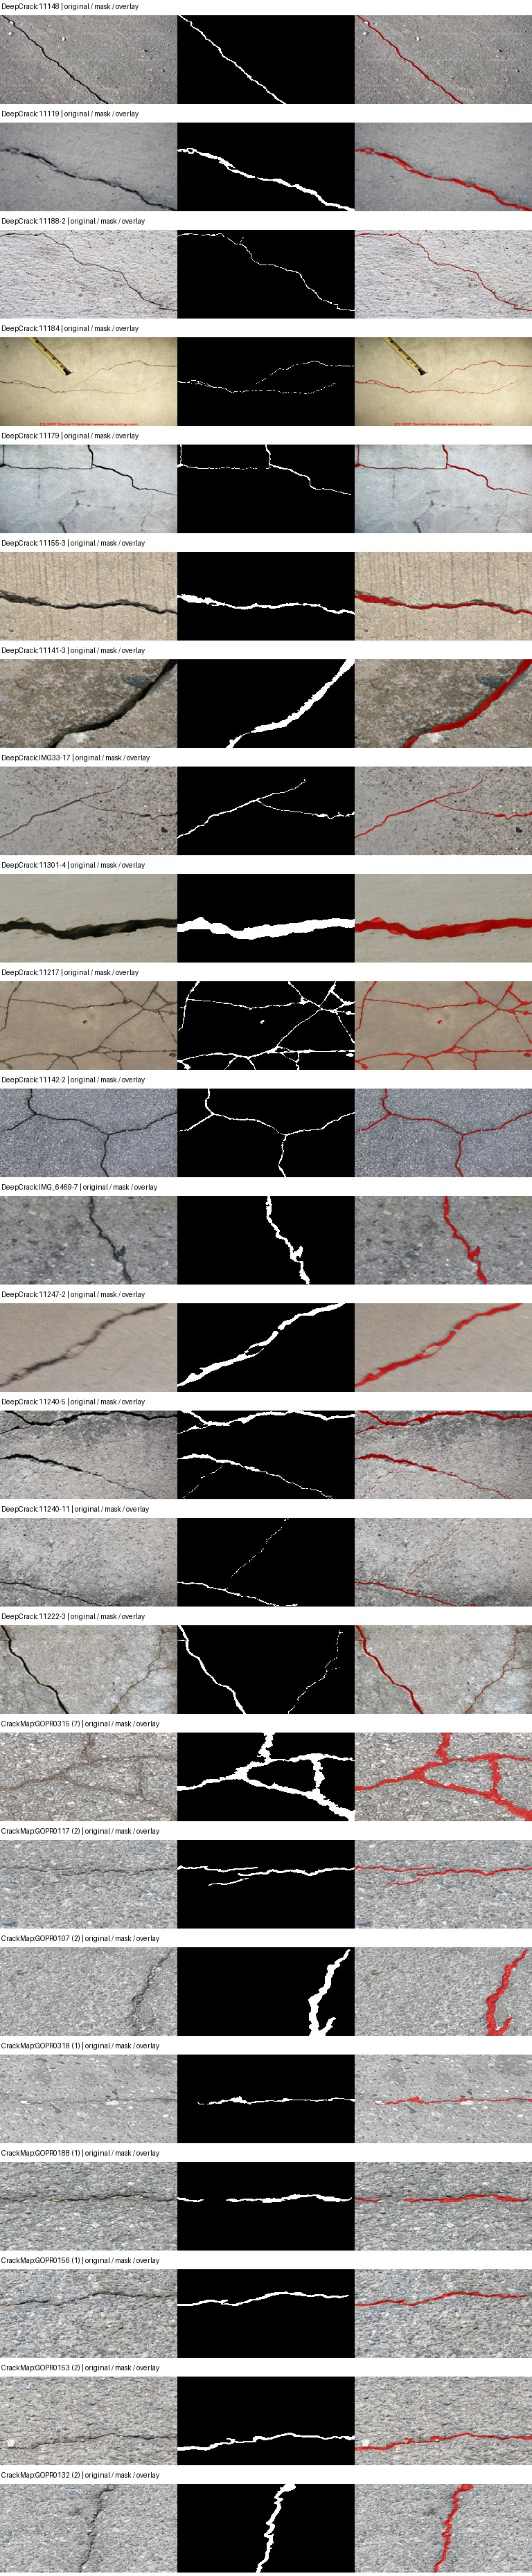

Review whether WHITE mask pixels follow actual cracks. Similarity groups do not verify capture independence.


In [11]:
from IPython.display import display, Image
sheet=run/'contact_sheet.jpg'
if sheet.exists():
    display(Image(filename=str(sheet)))
else:
    print('No contact sheet: inspect audit_report.json and inventory.json for pairing errors.')
print('Review whether WHITE mask pixels follow actual cracks. Similarity groups do not verify capture independence.')


In [12]:
import zipfile, hashlib
backup=Path('/kaggle/working/phase1_data_audit_v2.zip')
with zipfile.ZipFile(backup,'w',zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(run.rglob('*')):
        if path.is_file(): archive.write(path,path.relative_to(run).as_posix())
digest=hashlib.sha256(backup.read_bytes()).hexdigest()
backup.with_suffix('.zip.sha256').write_text(digest+'  '+backup.name+'\n')
print('Download from Kaggle Files/Output panel:',backup)
print('SHA256:',digest)
print('Copy the ZIP into your local DL_MINI_PROJECT folder for inspection. Raw datasets are excluded.')


Download from Kaggle Files/Output panel: /kaggle/working/phase1_data_audit_v2.zip
SHA256: e4066021729dd3c7f8ff6c8a541003cfea00dc2b8046b7567b122aeea3630f9d
Copy the ZIP into your local DL_MINI_PROJECT folder for inspection. Raw datasets are excluded.
